# RSNA Knee: Beyond the Leaderboard

**Xinyi Lu · retrospective research audit · 58 complete-label studies · 12 findings**

## tl;dr

The account has a verified **0.958 public leaderboard score**. In the cached Gold58 development run, the V13/V15 baseline has macro ROC AUC **0.938369**. Adding the fixed SWA checkpoint gives **0.940595**, a change of **+0.002226**, with conditional paired 95% interval **[-0.001006, +0.005772]**.

Removing R6 lowers AUC by **0.014553**. Removing the low-weight Reader changes ranks but no positive-negative ordering, leaving AUC unchanged in these 58 cases. Synovitis and Lateral OA remain the weakest classes.

**This is not independent validation.** Gold58 was repeatedly reused, including upstream checkpoint selection and a four-candidate screen. Intervals do not correct selection bias. V16's competition score was pending at collection. These are research results, not a validated clinical system.


## Context & Methods

This notebook regenerates the research presentation from **public aggregate summaries**. Study-level calculations were executed separately by `scripts/evaluate.py` against the authorized cached predictions; it checks study/label alignment, exact production-fusion parity and every AUC against scikit-learn. See `docs/METHODS.md` for details and `docs/DATA_ACCESS.md` for authorized metric recomputation.

### Key Assumptions

- Freeze existing checkpoints and coefficients; do not retrain or optimize on this analysis.
- Compare all 18 variants. R6 is a four-fold ensemble; Reader is a three-fold ensemble. These are not single checkpoints.
- Pair 2,000 ordinary study bootstrap draws across labels/variants (seed 20261021).
- Report conditional, pointwise 95% intervals without multiple-comparison or selection-bias adjustment.
- Also rerank every branch within bootstrap draws for a primary-contrast sensitivity check.
- Define descriptive Recall at percentile rank ≥0.5. It is not a calibrated probability cutoff.
- Patient identity and public-checkpoint training membership are unavailable; study bootstrap does not establish patient independence.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'results' / 'summary.json').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'results' / 'summary.json').is_file(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT / 'scripts'))
from render_figures import generate
_figures = generate(ROOT)
summary = json.loads((ROOT / 'results' / 'summary.json').read_text())
ablation = pd.read_csv(ROOT / 'results' / 'ablation.csv')
per_class = pd.read_csv(ROOT / 'results' / 'per_class.csv')
print(f"Studies: {summary['cohort_n']} | findings: {len(summary['labels'])} | paired draws: {summary['valid_resamples']}")
print('Analysis: cached-prediction replay; no new training or GPU image inference')


Studies: 58 | findings: 12 | paired draws: 2000
Analysis: cached-prediction replay; no new training or GPU image inference


## Data

The main source is the account's actual [V16 Gold58 screen](https://www.kaggle.com/code/andyyyyaa/rsna-knee-v16-gold58-weight-screen), using the V13/V15 production recipe as baseline. Raw medical data, reports, study identifiers and per-study predictions are excluded here. Hashes preserve input identity without republishing them. `competition_history.csv` comes from a read-only authenticated Kaggle API query.


In [2]:
display(per_class.loc[per_class.variant.eq('baseline_v13_v15'),
    ['label','positives','negatives','auc','auc_ci_low','auc_ci_high']].round(6).reset_index(drop=True))


,label,positives,negatives,auc,auc_ci_low,auc_ci_high
0,ACL,24,34,0.987745,0.961388,1.000000
1,MCL,9,49,0.963719,0.907157,0.998066
2,Medial Meniscus,26,32,0.978365,0.943182,1.000000
3,Lateral Meniscus,23,35,0.914286,0.830874,0.973812
4,Medial OA,15,43,0.990698,0.967521,1.000000
5,Lateral OA,11,47,0.847195,0.683753,0.975072
6,PF OA,21,37,0.886744,0.771053,0.973047
7,Effusion,35,23,0.980124,0.938128,1.000000
8,Synovitis,27,31,0.836320,0.719208,0.926642
9,Baker's,12,46,0.978261,0.931615,1.000000


## Results

### 1. Frozen ensemble ablation

Differences are relative to the complete V13/V15 recipe. Their uncertainty is paired, not inferred from overlap of independent model intervals. All extras, including poor-transfer checkpoints, remain in the table.


,variant,macro_auc,delta_vs_baseline,delta_ci_low,delta_ci_high
0,raptor384_single,0.922943,-0.015427,-0.025754,-0.005784
1,raptor224_single,0.916041,-0.022328,-0.035909,-0.010496
2,r6_fourfold,0.936579,-0.001790,-0.011649,0.008232
3,reader_threefold,0.915286,-0.023083,-0.041588,-0.007308
4,raptor384_224,0.923816,-0.014553,-0.024026,-0.005397
5,baseline_v13_v15,0.938369,0.000000,0.000000,0.000000
6,without_224,0.939222,0.000853,-0.002200,0.004294
7,without_r6,0.923816,-0.014553,-0.024026,-0.005397
8,without_reader,0.938369,0.000000,0.000000,0.000000
9,equal_class_weights,0.938298,-0.000072,-0.004094,0.004470


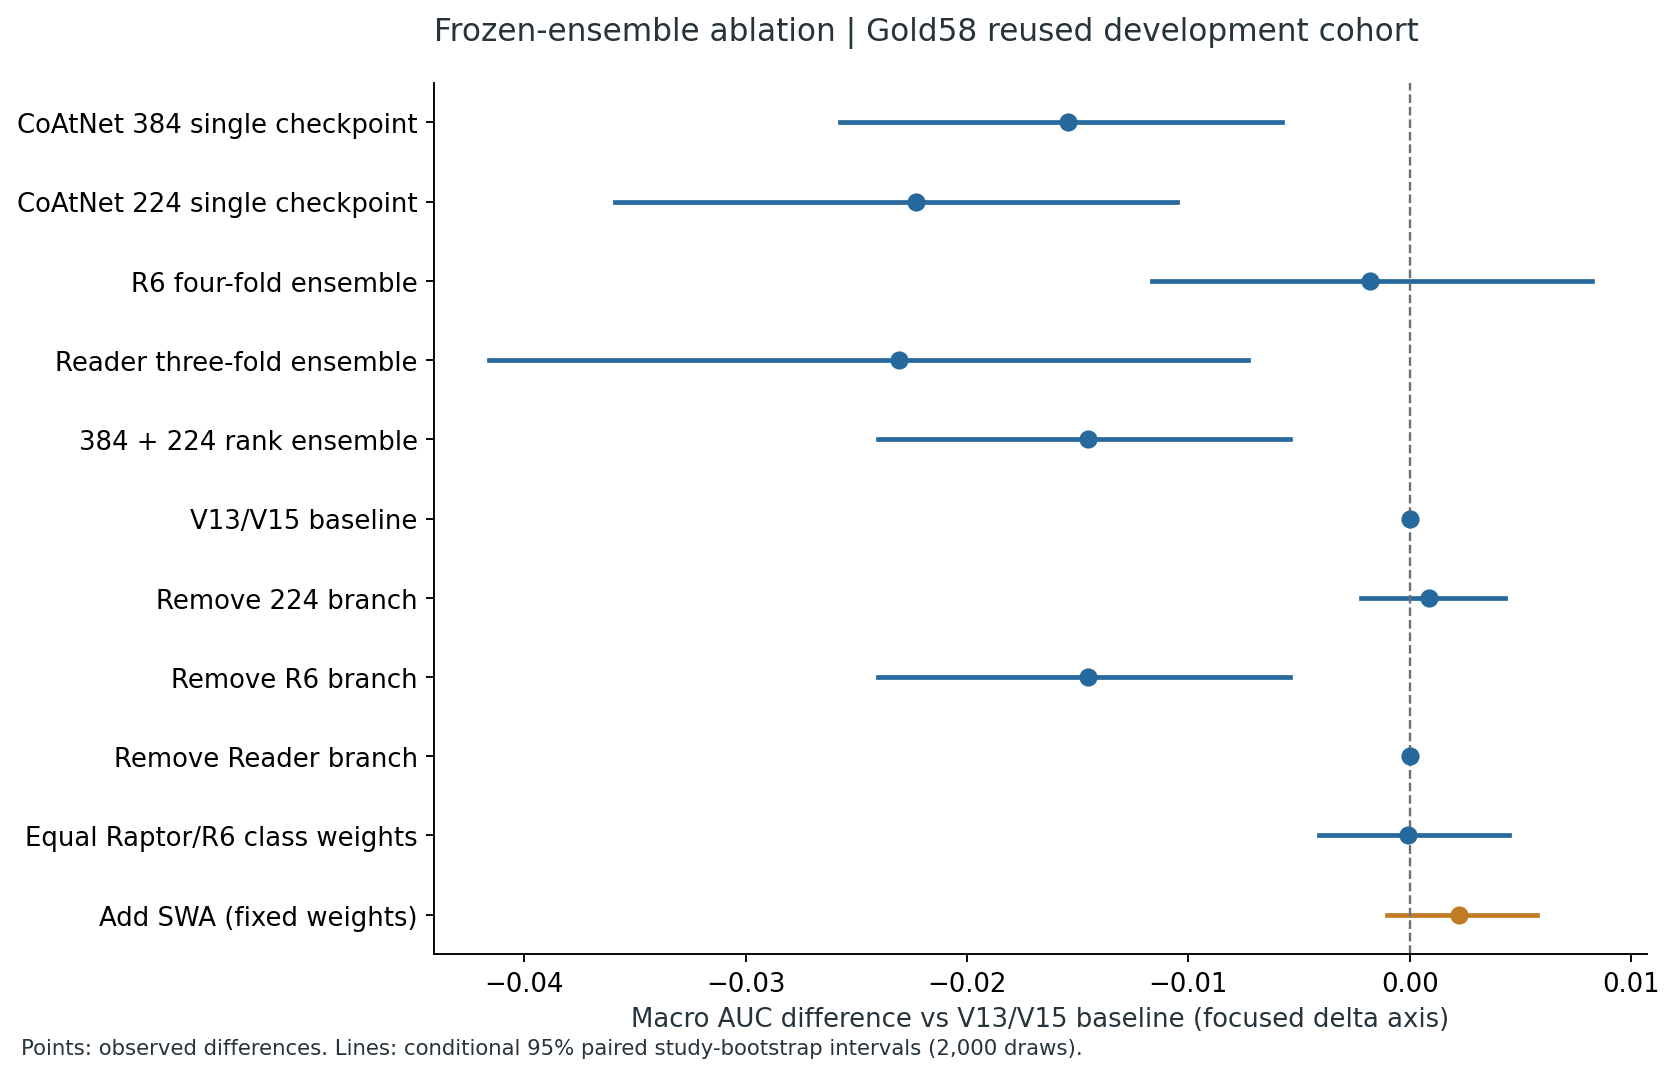

In [3]:
display(ablation[['variant','macro_auc','delta_vs_baseline','delta_ci_low','delta_ci_high']].round(6))
display(Image(filename=str(ROOT / 'figures' / 'ablation_forest.png')))


R6 removal shows the largest observed loss among branch removals. The SWA contrast and 224-removal contrast both have intervals crossing zero. The modest SWA point estimate is a development observation after prior screening, not a verified generalization gain.

### 2. Per-class performance and operating-point errors


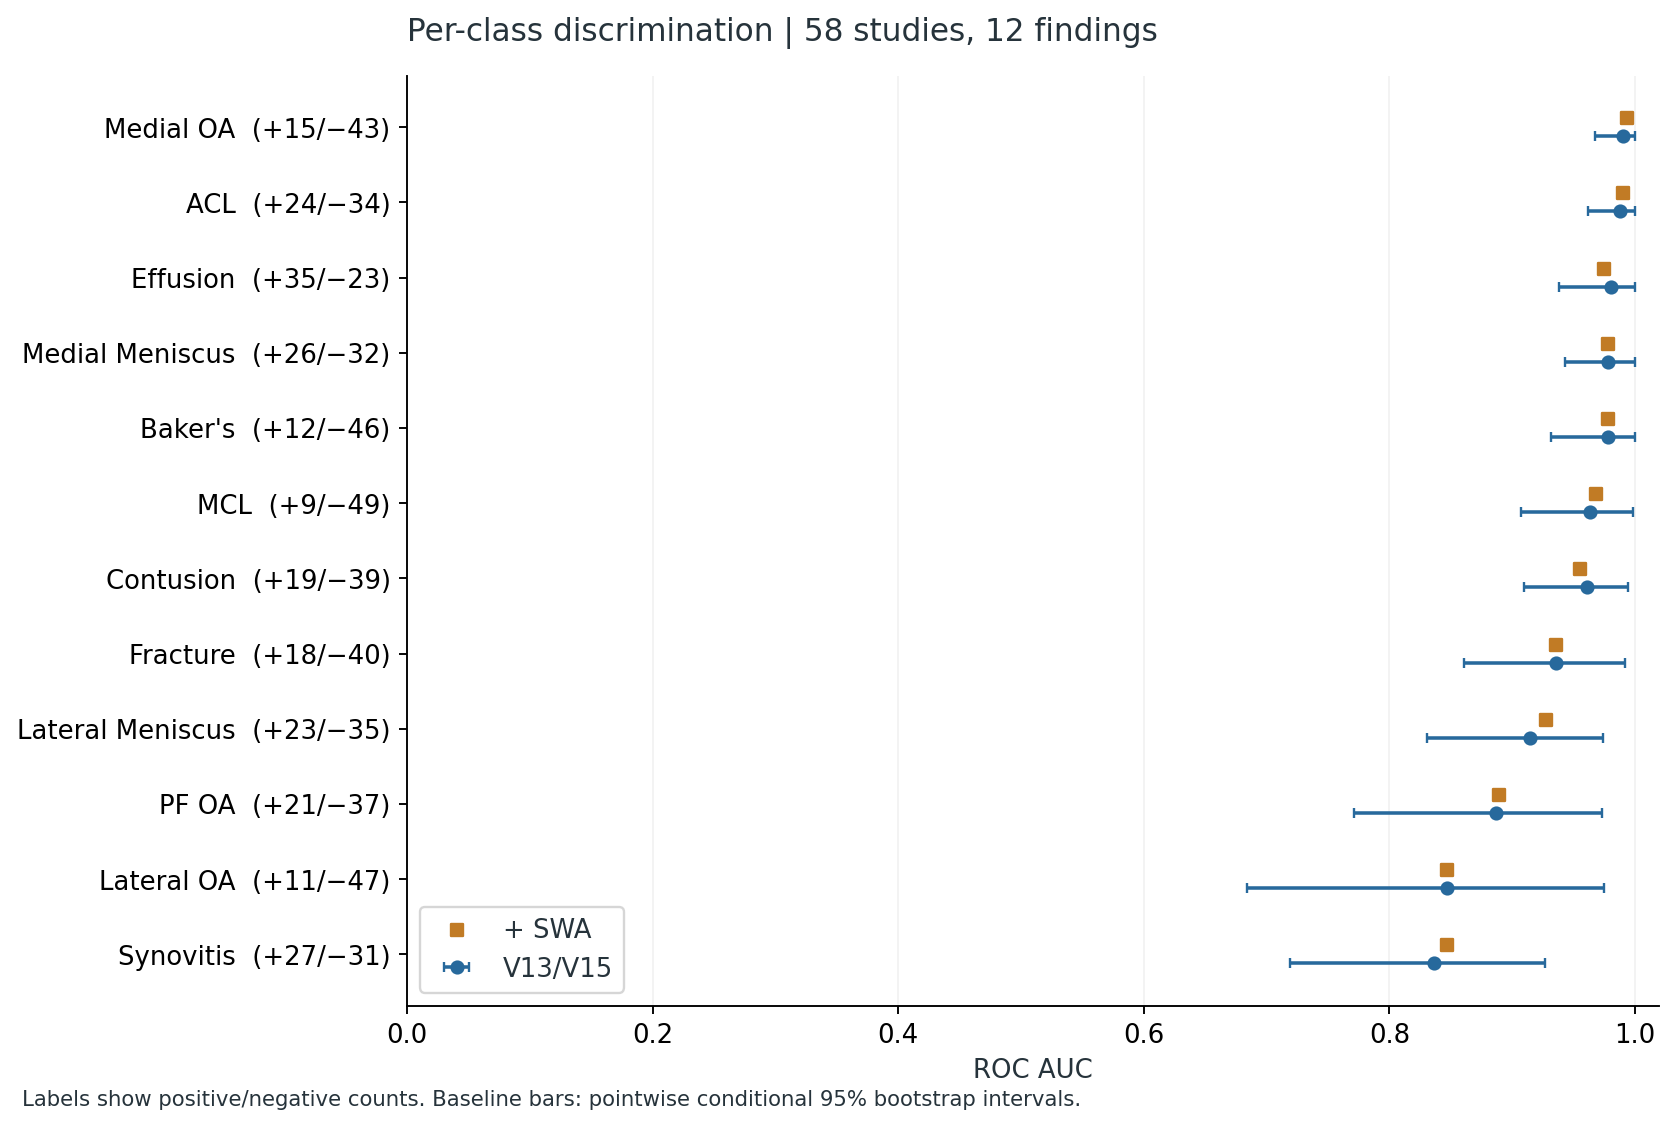

,label,recall,specificity,precision,tp,fn,fp,tn
0,ACL,1.0000,0.8235,0.8000,24,0,6,28
1,MCL,1.0000,0.5714,0.3000,9,0,21,28
2,Medial Meniscus,0.9615,0.8438,0.8333,25,1,5,27
3,Lateral Meniscus,0.8696,0.7143,0.6667,20,3,10,25
4,Medial OA,1.0000,0.6512,0.5000,15,0,15,28
5,Lateral OA,0.9091,0.5745,0.3333,10,1,20,27
6,PF OA,0.8095,0.6486,0.5667,17,4,13,24
7,Effusion,0.8286,0.9565,0.9667,29,6,1,22
8,Synovitis,0.7778,0.7097,0.7000,21,6,9,22
9,Baker's,1.0000,0.6087,0.4000,12,0,18,28


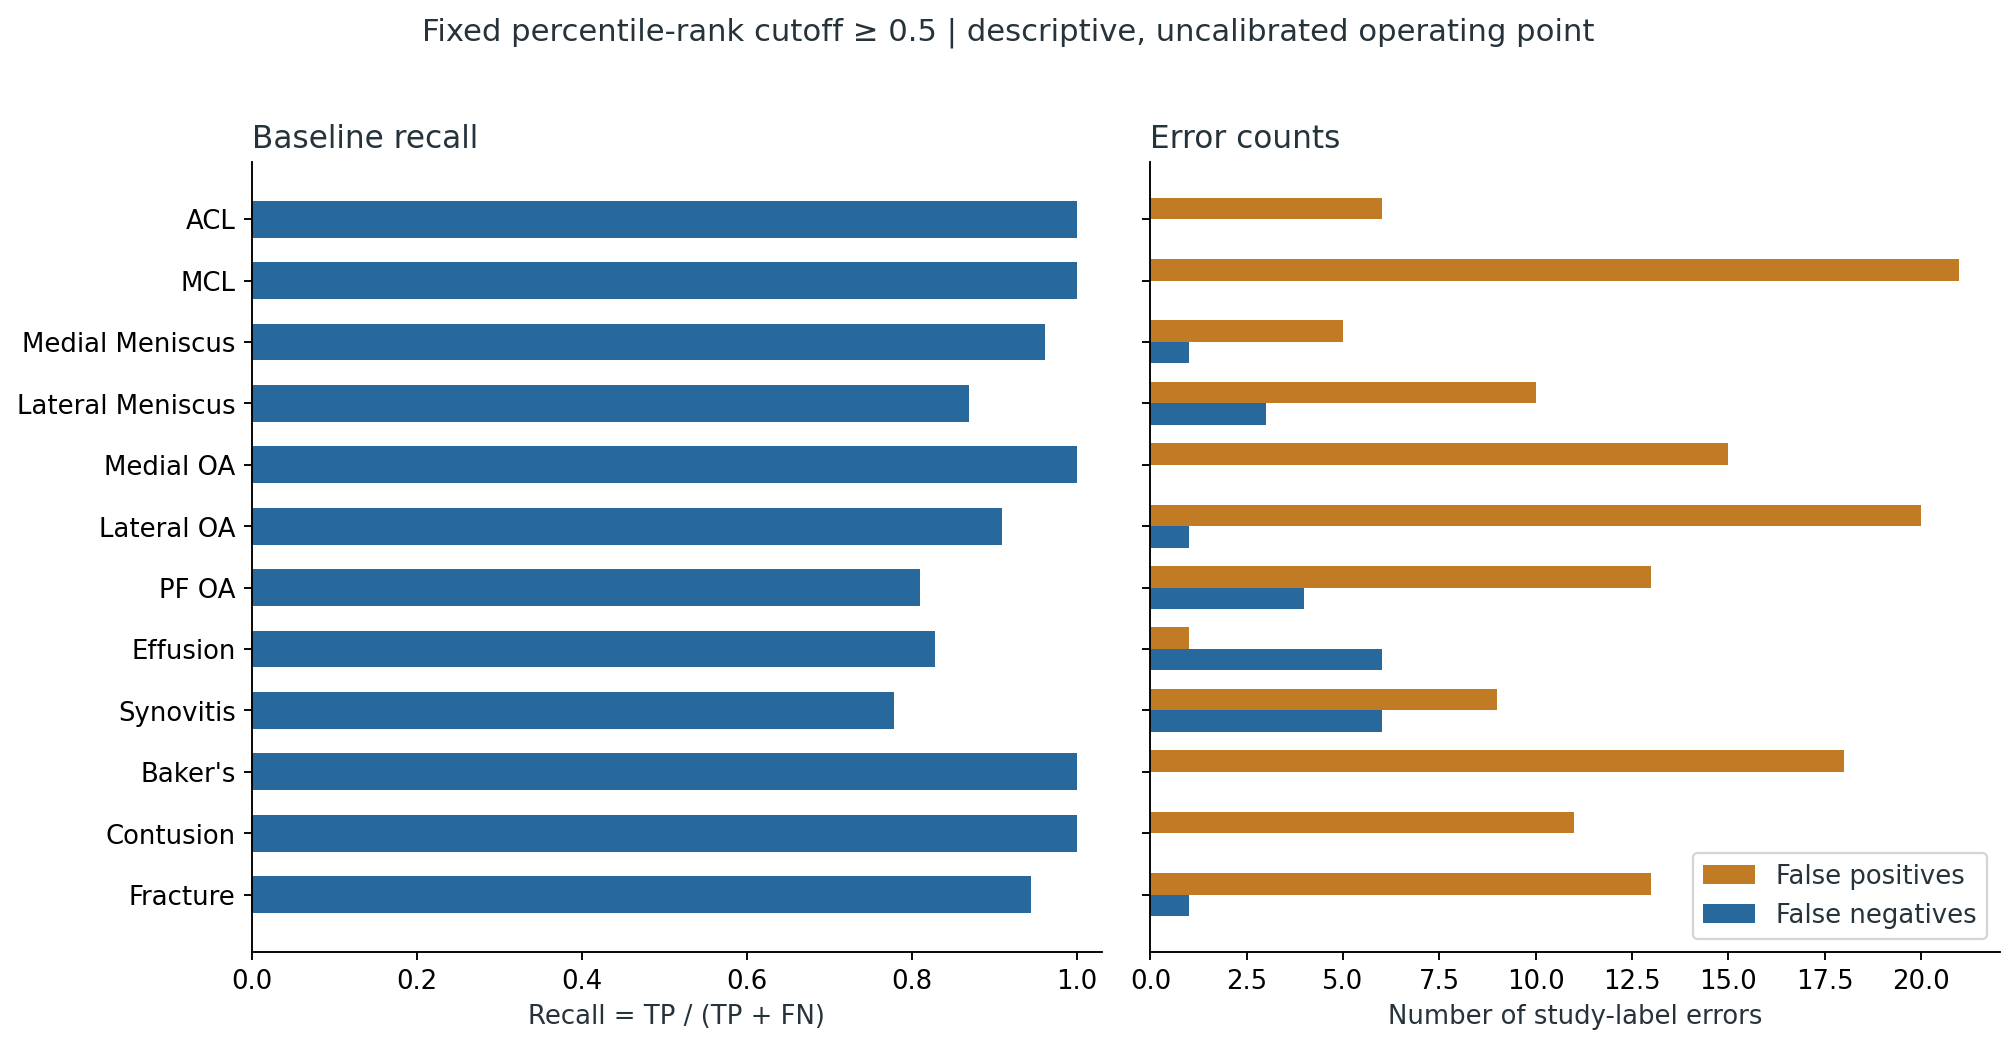

In [4]:
display(Image(filename=str(ROOT / 'figures' / 'per_class_auc.png')))
display(per_class.loc[per_class.variant.eq('baseline_v13_v15'),
    ['label','recall','specificity','precision','tp','fn','fp','tn']].round(4).reset_index(drop=True))
display(Image(filename=str(ROOT / 'figures' / 'recall_and_errors.png')))


Synovitis, Lateral OA and PF OA have the lowest baseline AUCs. SWA improves six AUCs, ties four and worsens Effusion and Contusion. The cutoff selects roughly half the cohort by rank, so the Recall table needs its specificity and class prevalence for interpretation. No individual case or radiological error diagnosis is published.

### 3. Complementarity and the Reader's unchanged AUC


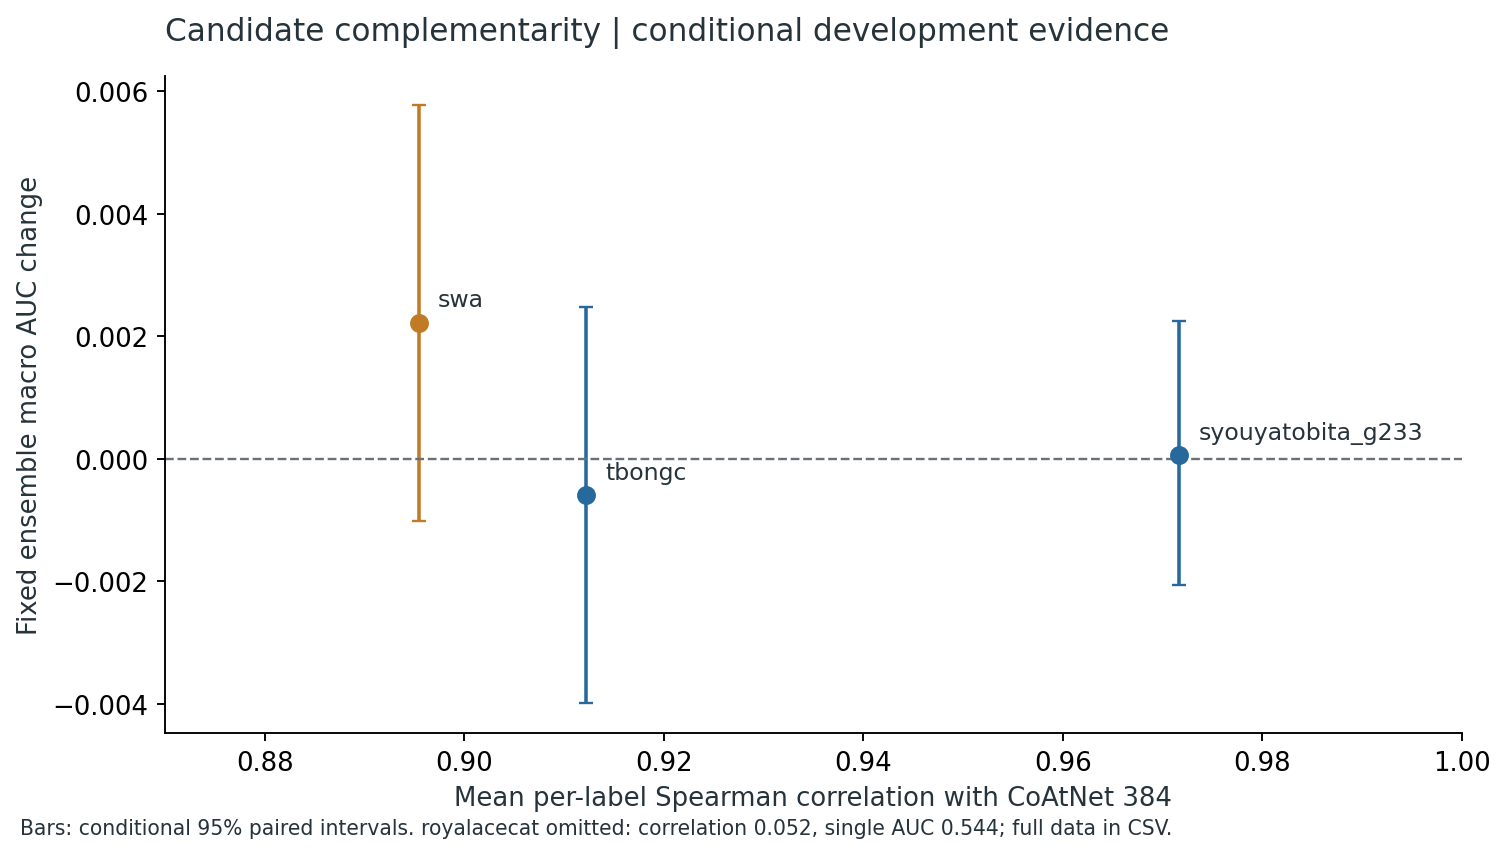

,changed_rank_cells,maximum_rank_difference,changed_positive_negative_pair_orderings
without_224,376.0,0.103448,56.0
without_r6,601.0,0.413793,267.0
without_reader,30.0,0.017241,0.0
extra_kawaharataishi_swa,382.0,0.103448,62.0


In [5]:
display(Image(filename=str(ROOT / 'figures' / 'complementarity.png')))
checks = json.loads((ROOT / 'results' / 'rank_structural_checks.json').read_text())
display(pd.DataFrame(checks).T)


The Reader moves 30 rank cells but no positive-negative pair ordering in this cohort. Its identical AUC therefore does not imply byte-identical predictions or prove that the branch has no value on a larger test set. SWA combines reasonable single-model discrimination and lower correlation; very low correlation alone does not ensure useful predictions.

### 4. Split and leakage audit


In [6]:
audit = json.loads((ROOT / 'results' / 'leakage_audit.json').read_text())
display(pd.DataFrame([
    ['Official Gold58 labels match', audit['official_gold_labels_match']],
    ['Historical adapter train/dev study overlap', audit['historical_local_adapter_split']['train_dev_study_overlap']],
    ['Historical adapter Gold58 overlap', audit['historical_local_adapter_split']['gold_train_overlap'] + audit['historical_local_adapter_split']['gold_dev_overlap']],
    ['Historical adapter train/dev normalized report overlap', audit['historical_local_adapter_split']['normalized_report_hash_train_dev_overlap']],
    ['Gold58 / other official normalized report hash overlap', audit['normalized_report_hash_overlap_gold_vs_other_studies']],
    ['Stable patient identifier in official table', audit['official_metadata_has_patient_identifier']],
], columns=['Check','Observed result']))
print(audit['patient_disjointness'])
print(audit['public_checkpoint_training_membership'])


,Check,Observed result
0,Official Gold58 labels match,True
1,Historical adapter train/dev study overlap,0
2,Historical adapter Gold58 overlap,0
3,Historical adapter train/dev normalized report...,0
4,Gold58 / other official normalized report hash...,1
5,Stable patient identifier in official table,False


NOT_VERIFIABLE: official train table has StudyInstanceUID and reports, no stable patient identifier
UNKNOWN: fold names and checkpoint filenames do not prove Gold58 exclusion


The historical local adapter split passes the stated study/report checks, but it is a different experiment from the public checkpoints used by V13/V15. One shared report hash is a duplication signal that may arise from templates; it is not proof of the same patient. Patient-level isolation remains unverified.

### 5. Supplementary preprocessing sensitivity and efficiency

The following sensitivity figure uses the **older Apex family** and archived image-inference outputs. It is kept separate from the main current-recipe conclusions. Noise and intensity corruption were not measured.


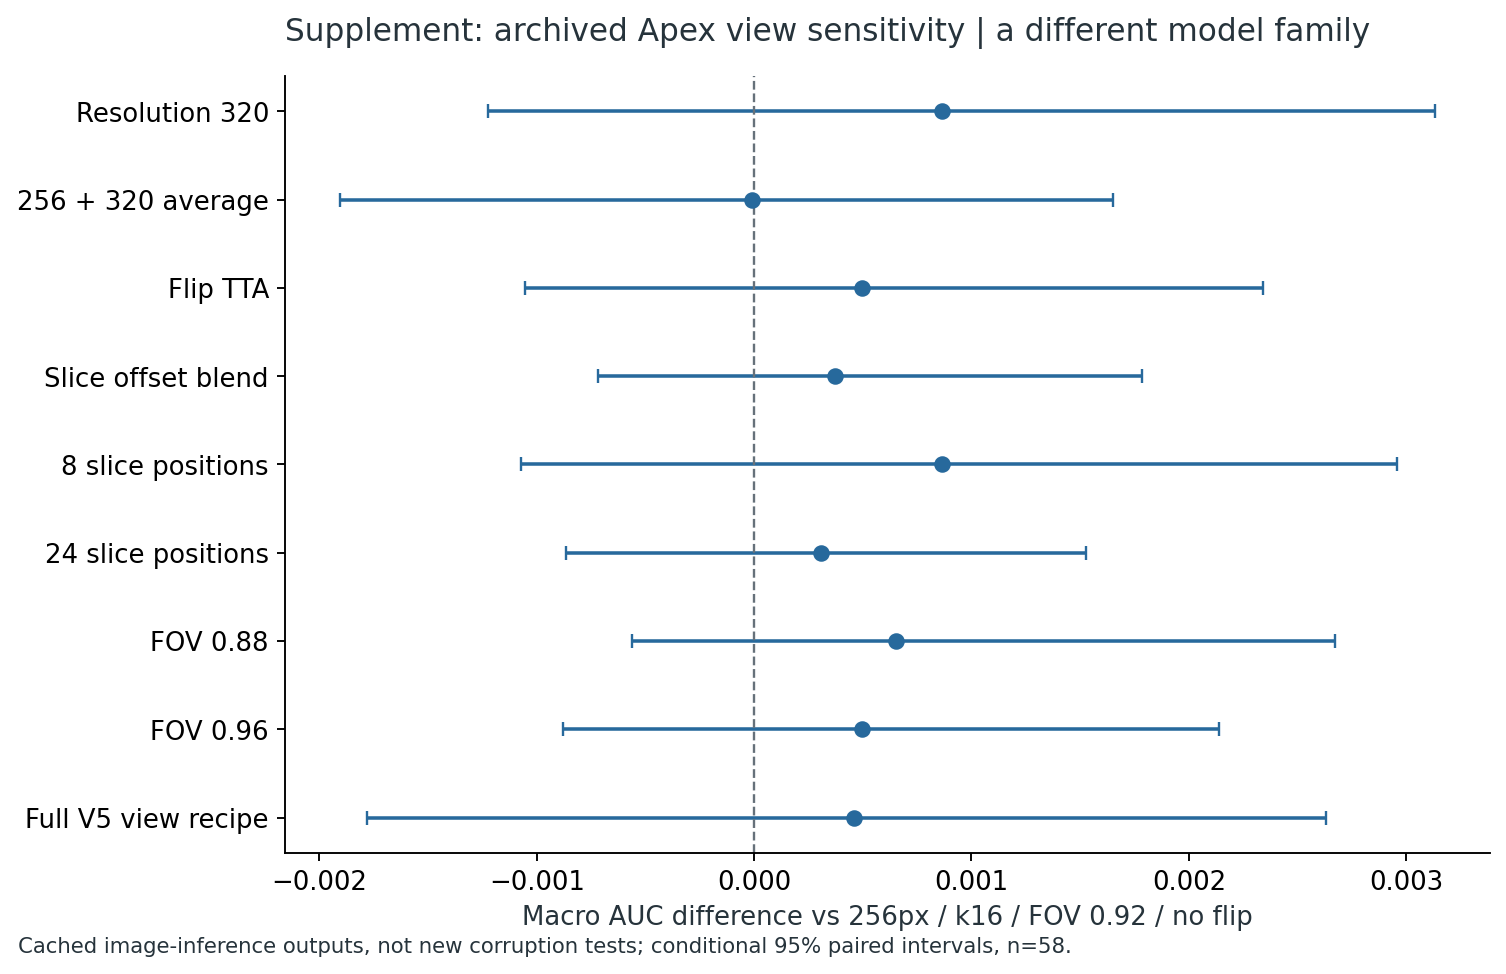

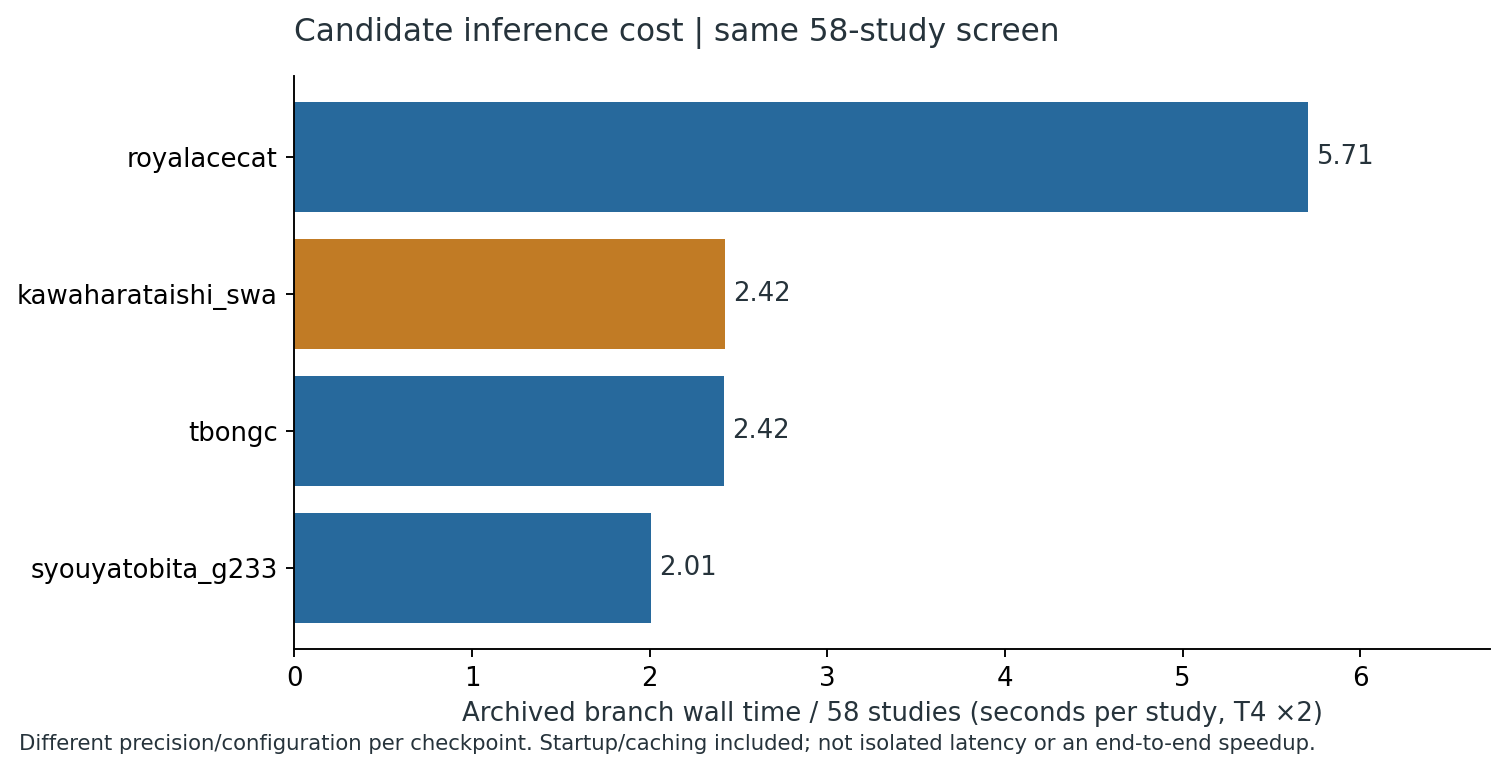

In [7]:
display(Image(filename=str(ROOT / 'figures' / 'legacy_view_sensitivity.png')))
display(Image(filename=str(ROOT / 'figures' / 'candidate_runtime.png')))


All displayed historical view-difference intervals cross zero. Candidate costs are matched 58-study wall times; different precision and cache behavior remain confounders. Peak GPU memory is unmeasured. The archived conservative SWA group projection is about 40,372 seconds for 1,300 studies, exceeding the original 7.5h gate; that projection is not actual hidden-test runtime.

## Takeaways

1. Identify a useful research question beyond the leaderboard: which components change discriminative ordering and where do they help or hurt?
2. Preserve uncertainty and negative findings. R6 contributes meaningfully in this fixed replay; evidence for the SWA addition remains conditional and inconclusive for future generalization.
3. Prioritize Synovitis/Lateral OA error review and an untouched patient/site-disjoint validation cohort with audited checkpoint training membership.
4. Treat preprocessing sensitivity, runtime and peak memory as separate measured questions. Do not replace missing image perturbation tests or memory measurements with assumptions.
5. Credit pretrained checkpoint authors separately from this repository's evaluation and interpretation work.

For a prospective follow-up, see `docs/NEXT_EXPERIMENT.md`. For source attribution and data-access boundaries, see `docs/ATTRIBUTION.md` and `docs/DATA_ACCESS.md`.
